    Лабораторная работа №01
    Прикладная статистика: Химический состав образцов керамики

В лабораторной работе использовался открытый датасет UC Irvine Machine Learning Repository: https://archive.ics.uci.edu/dataset/583/chemical+composition+of+ceramic+samples  Открытый репозиторий представляет нам кассификацию образцов древней китайской керамики - Longquan celadon на основе их химического состава на основе энергодисперсионной рентгеновской флуоресценции. Для изучения сырья и технологии обжига они отобрали 40 типичных осколков, относящихся к четырем культурным эпохам. В таблице представлены процентные содрежания таких соединений как: Na2O, MgO, Al2O3, SiO2, K2O, CaO, TiO2, Fe2O3, MnO, CuO, ZnO, PbO2, Rb2O, SrO, Y2O3, ZrO2, P2O5. Их содержание представлено в основах(body) и в глазури(glaze) остатков. 

Цель исследования: провести статистический анализ химического состава образцов керамики Longquan celadon; исследовать особенности распредления компонентов в body и glaze;  сравнить процентное содержание вещест в body и glaze в рамках 1 осататка керамики. 

В рамках данной лабораторной работы мы будем подробно изучать 4 случайные величины: процентное содержание Na2O в body, процентное содержание Na2O в glaze, процентное содержание Al2O3 в body, процентное содержание Al2O3 в glaze. Параметры являются случайными величинами, так как их содержание можно узнать только на основе измерения - энергодисперсионной рентгеновской флуоресценции. Мы не можем знать заранее точное содержание изучаемых оксидов. А образец керамики мы выбиарем случайно. Поэтому мы можем изучать данные случайные величины прикладной математической статистикой.

In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 0 Анализ исходных данных.
Исходный датасет содержит 88 наблюдений: 44 - body, 44 - glaze, 17 химических веществ.

In [7]:
df = pd.read_csv('Chemical Composion of Ceramic.csv')

df.head()

,Ceramic Name,Part,Na2O,MgO,Al2O3,SiO2,K2O,CaO,TiO2,Fe2O3,MnO,CuO,ZnO,PbO2,Rb2O,SrO,Y2O3,ZrO2,P2O5
0,FLQ-1-b,Body,0.62,0.38,19.61,71.99,4.84,0.31,0.07,1.18,630,10,70,10,430,0,40,80,90
1,FLQ-2-b,Body,0.57,0.47,21.19,70.09,4.98,0.49,0.09,1.12,380,20,80,40,430,-10,40,100,110
2,FLQ-3-b,Body,0.49,0.19,18.60,74.70,3.47,0.43,0.06,1.07,420,20,50,50,380,40,40,80,200
3,FLQ-4-b,Body,0.89,0.30,18.01,74.19,4.01,0.27,0.09,1.23,460,20,70,60,380,10,40,70,210
4,FLQ-5-b,Body,0.03,0.36,18.41,73.99,4.33,0.65,0.05,1.19,380,40,90,40,360,10,30,80,150


In [11]:
df.shape

(88, 19)

In [12]:
df.isnull().sum()

Ceramic Name    0
Part            0
Na2O            0
MgO             0
Al2O3           0
SiO2            0
K2O             0
CaO             0
TiO2            0
Fe2O3           0
MnO             0
CuO             0
ZnO             0
PbO2            0
Rb2O            0
SrO             0
Y2O3            0
ZrO2            0
P2O5            0
dtype: int64

In [15]:
df['Part'].value_counts()

Part
Body     44
Glaze    44
Name: count, dtype: int64

# 1 Na₂O в Body.

In [16]:
body = df[df['Part'] == 'Body']
body.head()

,Ceramic Name,Part,Na2O,MgO,Al2O3,SiO2,K2O,CaO,TiO2,Fe2O3,MnO,CuO,ZnO,PbO2,Rb2O,SrO,Y2O3,ZrO2,P2O5
0,FLQ-1-b,Body,0.62,0.38,19.61,71.99,4.84,0.31,0.07,1.18,630,10,70,10,430,0,40,80,90
1,FLQ-2-b,Body,0.57,0.47,21.19,70.09,4.98,0.49,0.09,1.12,380,20,80,40,430,-10,40,100,110
2,FLQ-3-b,Body,0.49,0.19,18.60,74.70,3.47,0.43,0.06,1.07,420,20,50,50,380,40,40,80,200
3,FLQ-4-b,Body,0.89,0.30,18.01,74.19,4.01,0.27,0.09,1.23,460,20,70,60,380,10,40,70,210
4,FLQ-5-b,Body,0.03,0.36,18.41,73.99,4.33,0.65,0.05,1.19,380,40,90,40,360,10,30,80,150


In [17]:
x1 = body['Na2O']
x1.head()

0    0.62
1    0.57
2    0.49
3    0.89
4    0.03
Name: Na2O, dtype: float64

In [19]:
round(x1.mean(), 4)

np.float64(0.3975)

In [20]:
x1.median()

np.float64(0.37)

In [21]:
x1.var()

np.float64(0.044730813953488366)

In [22]:
x1.std()

np.float64(0.2114966050637418)

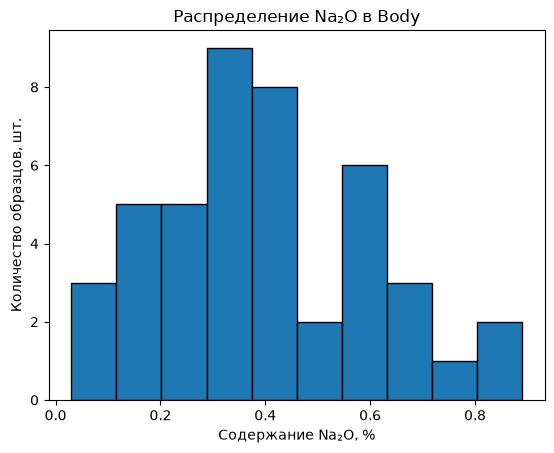

In [26]:
plt.hist(x1, edgecolor='black')

plt.xlabel('Содержание Na₂O, %')
plt.ylabel('Количество образцов, шт.')
plt.title('Распределение Na₂O в Body')

plt.show()

In [28]:
x1.skew()

np.float64(0.39985206718508237)

In [29]:
x1.min()

np.float64(0.03)

In [30]:
x1.max()

np.float64(0.89)

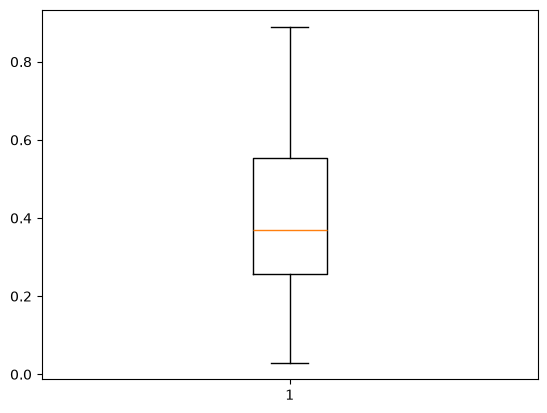

In [32]:
plt.boxplot(x1)
plt.show()

In [33]:
q1 = x1.quantile(0.25)
q3 = x1.quantile(0.75)

iqr = q3 - q1
print(iqr)

0.295


In [34]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print(lower, upper)

-0.185 0.995
